# 📸 Day 16 · Collaborative map: Tashkent through strangers' eyes

**#30DayMapChallenge Uzbekistan 2026** · beginner tutorial, no experience needed

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/NodiraTillayeva/30DayMapChallengeUzbekistan/blob/main/2026/Day%2016%20Collaborative%20map/tutorial/day16_street_photos.ipynb)

**Mapillary** is a map of street photos taken by anyone with a phone. In Tashkent, 47 people who mostly never met each other took **107,288 photos**, and together they made one map.

In this notebook you will:
1. find out **who** photographed Tashkent, and **when**,
2. draw the city with one colour per person,
3. walk along their photo trails on an interactive map,
4. look at real street photos with your own Mapillary key,
5. map the photos of **your own group**.

Run the cells from top to bottom: click a cell, then press **Shift + Enter**.

## Step 0 · Get ready

`tashkent_photos.parquet` has one row per photo: its **id**, **lon** and **lat**, the **date**, the **creator** (the Mapillary username of the person who took it) and the **sequence** (one walk or drive, a chain of photos).

In [1]:
import pandas as pd
import matplotlib.pyplot as plt

BASE = "https://raw.githubusercontent.com/NodiraTillayeva/30DayMapChallengeUzbekistan/main/2026/Day%2016%20Collaborative%20map/tutorial/data/"

photos = pd.read_parquet(BASE + "tashkent_photos.parquet")
print(f"Ready! ✅ {len(photos):,} photos") 
photos.head()

Ready! ✅ 107,288 photos


,id,lon,lat,date,creator,sequence
0,295890252169313,69.273498,41.269239,2017-01-01,s_alisher,-5bD4toq0ayzrm4GYP_mfA
1,294149428913741,69.275531,41.269605,2017-07-02,s_alisher,-5bD4toq0ayzrm4GYP_mfA
2,152185903514660,69.275515,41.269597,2017-07-02,s_alisher,-5bD4toq0ayzrm4GYP_mfA
3,327277125491034,69.275510,41.269593,2017-07-02,s_alisher,-5bD4toq0ayzrm4GYP_mfA
4,200804474995862,69.275499,41.269589,2017-07-02,s_alisher,-5bD4toq0ayzrm4GYP_mfA


## Step 1 · Who took the photos?

`value_counts()` counts how many photos each person took.

47 people, 877 walks and drives


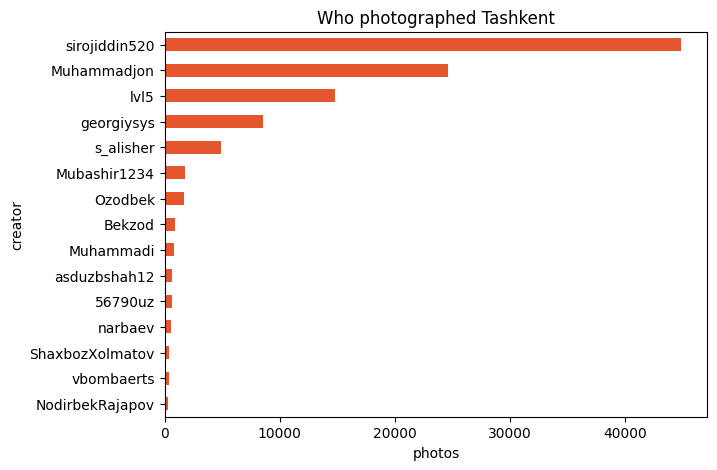

In [2]:
people = photos["creator"].value_counts()
print(len(people), "people,", photos["sequence"].nunique(), "walks and drives")

people.head(15).sort_values().plot.barh(figsize=(7, 5), color="#e4572e")
plt.xlabel("photos")
plt.title("Who photographed Tashkent") 
plt.show()

## Step 2 · One colour per person

Each dot is one photo. The 8 people with the most photos get their own colour, everyone else is grey. Nobody planned this map: each line is one person's trip.

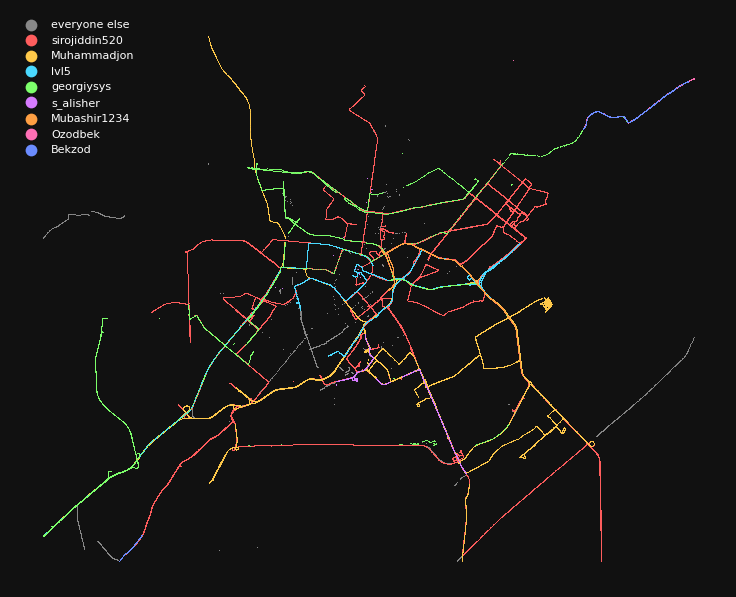

In [3]:
top = people.index[:8]
colours = ["#ff5d5d", "#ffc94a", "#4ad9ff", "#7dff6b", "#d77bff", "#ff9f43", "#ff6fb5", "#6b8cff"]

fig, ax = plt.subplots(figsize=(10, 7.5), facecolor="#111")
ax.set_facecolor("#111")

others = photos[~photos["creator"].isin(top)]
ax.scatter(others["lon"], others["lat"], s=0.5, c="#888", linewidths=0, label="everyone else")

for name, colour in zip(top, colours):
    mine = photos[photos["creator"] == name]
    ax.scatter(mine["lon"], mine["lat"], s=0.5, c=colour, linewidths=0, label=name)

ax.set_aspect(1.33) 
ax.axis("off")
ax.legend(markerscale=12, frameon=False, labelcolor="white", fontsize=8, loc="upper left")
plt.show()

## Step 3 · When?

The same streets were photographed again and again over the years. `photos["date"].str[:4]` takes the first 4 characters of the date: the year.

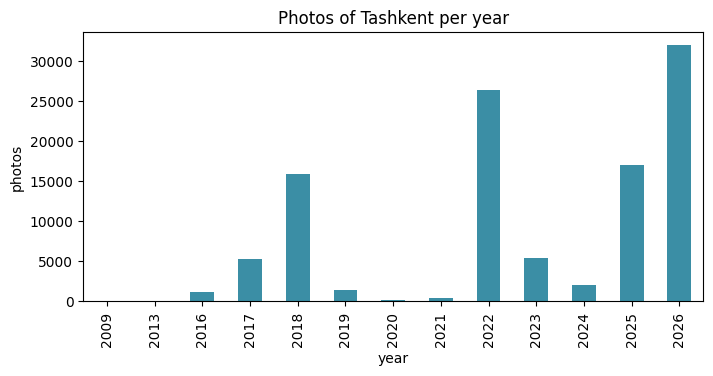

In [4]:
photos["year"] = photos["date"].str[:4]
photos["year"].value_counts().sort_index().plot.bar(figsize=(8, 3.5), color="#3b8ea5")
plt.ylabel("photos")
plt.title("Photos of Tashkent per year") 
plt.show()

## Step 4 · Walk along the trails

**folium** makes an interactive map. Each walk or drive is one line, in the colour of the person who made it. Click a line to see who made it and when, then click **Open the photos** to walk along it on Mapillary.

In [5]:
import folium

m = folium.Map(location=[41.31, 69.27], zoom_start=12, tiles="Esri.WorldGrayCanvas")
colour_of = dict(zip(top, colours))

for seq, walk in photos.groupby("sequence"):
    walk = walk.iloc[::5]                      # every 5th photo is enough for a line
    if len(walk) < 2:
        continue
    first = walk.iloc[0]
    link = f"https://www.mapillary.com/app/?pKey={first['id']}&focus=photo"
    popup = f"<b>{first['creator']}</b><br>{first['date']}<br>{len(walk) * 5} photos<br><a href='{link}' target='_blank'>Open the photos ↗</a>"
    folium.PolyLine(walk[["lat", "lon"]].values, color=colour_of.get(first["creator"], "#777"),
                    weight=3, opacity=0.8, popup=popup).add_to(m)
m

## Step 5 · Look at real photos

To get the photos themselves, you need a free **Mapillary key** (a *client token*, it starts with `MLY|`). The README explains how to get one in 3 minutes.

Run the cell and paste your key into the box. `getpass` hides it, so it isn't saved in the notebook.

Two strangers photographed the same place, the **Amir Timur statue**: one in 2017, one in 2018.

In [ ]:
from getpass import getpass
import requests
from IPython.display import Image, display

TOKEN = getpass("Paste your Mapillary key (MLY|...): ")

def show_photo(photo_id):
    url = f"https://graph.mapillary.com/{photo_id}"
    info = requests.get(url, params={"access_token": TOKEN,
                                     "fields": "thumb_1024_url,captured_at,creator"}).json()
    date = pd.to_datetime(info["captured_at"], unit="ms").date()
    print(f"📸 {info['creator']['username']}, {date}")
    display(Image(url=info["thumb_1024_url"], width=600))

show_photo(370582994281407)
show_photo(498977037906489)

## Step 6 · Your group's map

After your group walk (see the README), put your **usernames** and a **small box** around your streets. The cell asks Mapillary for all photos in the box, keeps only your group's, and puts them on a map.

> The box must be small, about 3 × 3 km at most, or Mapillary says no. Find the four numbers (west, south, east, north) on [bboxfinder.com](http://bboxfinder.com).

As an example, we use two people who photographed the centre of Tashkent. Change them to your own names.

In [ ]:
USERNAMES = ["georgiysys", "Mubashir1234"]     # 👈 your group's Mapillary usernames
BOX = [69.26, 41.30, 69.30, 41.33]          # 👈 west, south, east, north

rows = []
for name in USERNAMES:
    r = requests.get("https://graph.mapillary.com/images",
                     params={"access_token": TOKEN, "bbox": ",".join(map(str, BOX)),
                             "creator_username": name, "fields": "id,geometry,captured_at",
                             "limit": 2000}).json()
    for p in r.get("data", []):
        lon, lat = p["geometry"]["coordinates"]
        rows.append({"creator": name, "lon": lon, "lat": lat,
                     "date": str(pd.to_datetime(p["captured_at"], unit="ms").date()), "id": p["id"]})
    print(name, len(r.get("data", [])), "photos")

group = pd.DataFrame(rows)

m2 = folium.Map(location=[(BOX[1] + BOX[3]) / 2, (BOX[0] + BOX[2]) / 2], zoom_start=14, tiles="Esri.WorldGrayCanvas")
group_colours = ["#e4572e", "#2e86ab", "#59a96a", "#9b5de5", "#f4a259", "#ef476f"]
for name, colour in zip(USERNAMES, group_colours):
    for _, p in group[group["creator"] == name].iterrows():
        folium.CircleMarker([p["lat"], p["lon"]], radius=3, color=colour, fill=True, weight=0, fill_opacity=0.9,
                            popup=f"<b>{name}</b><br>{p['date']}<br><a href='https://www.mapillary.com/app/?pKey={p['id']}&focus=photo' target='_blank'>Open ↗</a>").add_to(m2)
m2

## Step 7 · Save your map

The map from Step 2 again, sharper (`dpi=300`), without the legend, saved as **tashkent_together.png** and downloaded.

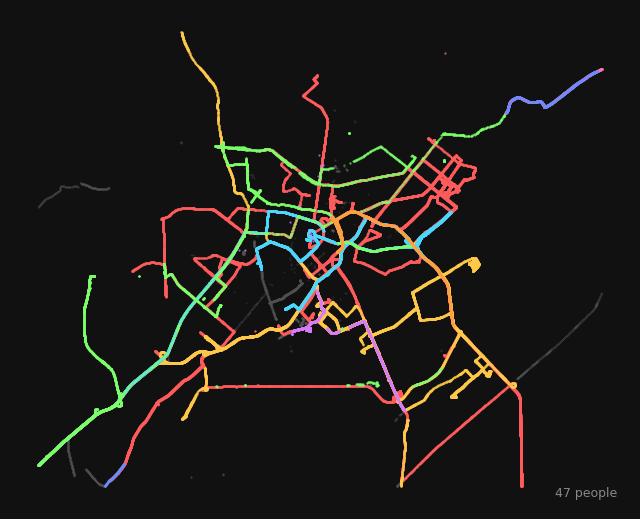

Saved to Downloads\tashkent_together.png! ✅


In [6]:
fig, ax = plt.subplots(figsize=(8, 8), facecolor="#111111")
ax.set_facecolor("#111111")

other = photos[~photos["creator"].isin(top)]
ax.scatter(other["lon"], other["lat"], s=0.15, c="#555555", alpha=0.4)

for name, colour in zip(top, colours):
    p = photos[photos["creator"] == name]
    ax.scatter(p["lon"], p["lat"], s=0.3, c=colour, alpha=0.8)

ax.text(0.98, 0.02, f"{photos['creator'].nunique()} people",
        transform=ax.transAxes, ha="right", va="bottom",
        color="#888888", fontsize=9)
ax.set_aspect(1.33)
ax.set_axis_off()

plt.savefig(r"C:\Users\Asus\Downloads\tashkent_together.png", dpi=300, facecolor="#111111", bbox_inches="tight")
plt.show()
print("Saved to Downloads\\tashkent_together.png! ✅")
